# s2 — skip-safety metric analysis

s2 sweep: contiguous skips of length 1–4, 4 backbones × {CIFAR-100, ImageNet-1k}. Inputs are `analysis/grouped_metrics_s2_*.csv` (from `python metric_experiments/build_group_stats.py --group s2`) plus the s2 accuracy CSVs.

Two evaluation measures, both computed per (model, dataset) combo:

- **Spearman's rank correlation** between the metric and the true accuracy of each skip. Every metric is sign-corrected first so that **higher = more similar to the original model = safer to skip**; a positive rho therefore always means the metric points the right way, and a negative rho means it ranks skips backwards.
- **Average top-5 damage** (used instead of precision/recall). Damage is the accuracy lost by a skip: baseline model accuracy minus approximated model accuracy. We take the mean over the 5 best-ranked skips by that metric to get the average top-5 damage. The metric with the smallest average top-5 damage is the best for that model/dataset combo. Shown in percentage points; it can be slightly negative where a skip beats the unskipped baseline.

Each heatmap cell also carries a p-value. For rho it is the two-sided Spearman test (H0: rho = 0). For top-5 damage it is a one-sided permutation test against picking 5 skips at random from the same combo: the fraction of random 5-skip draws whose average damage is at most the metric's (H0: the metric's top 5 are no better than random). p-values are uncorrected for multiple comparisons.

Figures are saved to `../figures/`.

In [1]:
import ast
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from scipy.stats import spearmanr

S2 = Path.cwd().resolve()
if S2.name == "analysis":
    S2 = S2.parent
ANALYSIS, FIG_DIR = S2 / "analysis", S2 / "figures"
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)

MODELS = {"deitsmall": "DeiT-S", "vitsmall": "ViT-S", "dinov2base": "DINOv2-B", "vitlarge": "ViT-L"}
DATASETS = {"cifar100": "CIFAR-100", "imagenet1k": "ImageNet-1k"}

# Thesis metrics, in plot order, grouped by where they are measured.
THESIS_METRICS = {
    "toast_linear_error": "Linear approx. error (TOAST)",
    "angular_dist": "Angular distance",
    "local_cka": "Local CKA",
    "cka_embed": "Global CKA",
    "cosine_sim": "Cosine similarity",
    "mse": "MSE",
    "orig_head_accuracy": "Pretrained head accuracy",
    "kl_div": "KL divergence",
}
TIERS = [("Local (skip boundary)", 3), ("Global (final embedding)", 3), ("Pretrained head", 2)]

# Every other stage-1 metric, for the appendix.
OTHER_METRICS = {
    "knn_overlap@5": "kNN overlap@5",
    "knn_overlap@10": "kNN overlap@10",
    "participation_ratio_change": "Participation ratio change",
    "probe_frozen_accuracy": "Frozen linear probe accuracy",
    "probe_refit_accuracy": "Refit linear probe accuracy",
    "top1_flip_pct": "Top-1 flip rate",
    "entropy_delta": "Entropy change",
}

# Raw value grows with dissimilarity -> negated so higher = safer for every metric.
N_PERM = 20_000  # random 5-skip draws per combo for the top-5 damage p-value

DISSIMILARITY_METRICS = {"toast_linear_error", "angular_dist", "mse", "kl_div", "top1_flip_pct",
                         "entropy_delta", "participation_ratio_change"}

## Load

One row per (model, dataset, span). `orig_head_accuracy` (pretrained head accuracy) is not a stage-1 metric: it comes from the s2 accuracy sweep (the frozen original ImageNet head on the skipped model), so it and KL divergence only exist for DeiT-S, ViT-S and ViT-L on ImageNet-1k. DINOv2-B has no classification head.

In [2]:
def _span(approx_layer):
    parsed = ast.literal_eval(approx_layer)
    return f"({parsed[0][0]},{parsed[0][1]})" if len(parsed) == 1 else None


frames, baselines = [], {}
for model in MODELS:
    for tag in DATASETS:
        g = pd.read_csv(ANALYSIS / f"grouped_metrics_s2_{model}_{tag}.csv")
        acc = pd.read_csv(S2 / "accuracies" / f"accuracies_results_{model}_{tag}.csv")
        baselines[(model, tag)] = acc.loc[acc["approx_layer"] == "[]", "accuracy_mean"].iloc[0]
        acc["span"] = acc["approx_layer"].apply(_span)
        g = g.merge(acc[["span", "orig_head_accuracy_mean"]].rename(
            columns={"orig_head_accuracy_mean": "orig_head_accuracy"}), on="span", how="left")
        g.insert(0, "dataset", tag)
        g.insert(0, "model", model)
        frames.append(g)
raw = pd.concat(frames, ignore_index=True)

df = raw.copy()
for m in DISSIMILARITY_METRICS:
    df[m] = -df[m]

combos = list(raw.groupby(["model", "dataset"], sort=False).groups)
summary = raw.groupby(["model", "dataset"], sort=False).agg(
    spans=("span", "size"), best_skip_acc=("true_accuracy", "max"), best_span=("span", "first"))
summary.insert(0, "baseline_acc", [baselines[c] for c in summary.index])
summary

baseline_acc  spans  best_skip_acc best_span
model      dataset                                                 
deitsmall  cifar100        0.712400     38       0.717733   (10,11)
           imagenet1k      0.737933     38       0.736900   (10,11)
vitsmall   cifar100        0.819467     38       0.799833     (4,5)
           imagenet1k      0.735700     38       0.716200     (3,4)
dinov2base cifar100        0.869567     38       0.862500     (0,1)
           imagenet1k      0.747667     38       0.735967     (2,3)
vitlarge   cifar100        0.857767     86       0.864100   (21,22)
           imagenet1k      0.785633     86       0.784833     (3,4)

### Polarity check

The sign correction must match the data: every flipped metric should correlate negatively with true accuracy before flipping, every other metric positively, and the corrected rho must be exactly −1 × raw for flipped metrics. A combo against the expected sign is a genuine wrong-direction result, not a polarity bug (TOAST on DeiT-S / CIFAR-100 is the only one).

In [3]:
polarity = []
for m in {**THESIS_METRICS}:
    raw_r, cor_r = [], []
    for key in combos:
        idx = raw[(raw["model"] == key[0]) & (raw["dataset"] == key[1])].dropna(subset=[m]).index
        if len(idx) < 3:
            continue
        raw_r.append(spearmanr(raw.loc[idx, m], raw.loc[idx, "true_accuracy"])[0])
        cor_r.append(spearmanr(df.loc[idx, m], df.loc[idx, "true_accuracy"])[0])
    raw_r, cor_r = np.array(raw_r), np.array(cor_r)
    flipped = m in DISSIMILARITY_METRICS
    polarity.append({
        "metric": THESIS_METRICS[m], "flipped": flipped,
        "raw rho > 0": int((raw_r > 0).sum()), "raw rho < 0": int((raw_r < 0).sum()),
        "median raw rho": np.median(raw_r),
        "corrected = ±raw": np.allclose(cor_r, -raw_r if flipped else raw_r),
    })
polarity = pd.DataFrame(polarity).set_index("metric")
polarity["sign check"] = np.where(polarity["flipped"], polarity["median raw rho"] < 0, polarity["median raw rho"] > 0)
assert polarity["sign check"].all() and polarity["corrected = ±raw"].all()
polarity.round(2)

,flipped,raw rho > 0,raw rho < 0,median raw rho,corrected = ±raw,sign check
metric,,,,,,
Linear approx. error (TOAST),True,1,7,-0.38,True,True
Angular distance,True,0,8,-0.85,True,True
Local CKA,False,8,0,0.75,True,True
Global CKA,False,8,0,0.61,True,True
Cosine similarity,False,8,0,0.68,True,True
MSE,True,0,8,-0.71,True,True
Pretrained head accuracy,False,3,0,0.98,True,True
KL divergence,True,0,3,-0.79,True,True


## Spearman rho and average top-5 damage

Rows are (model, dataset) combos; a metric with no values for a combo (the head metrics outside ImageNet-1k head models) is left as NaN.

In [4]:
def evaluate(metrics):
    rho, rho_p, damage, damage_p = {}, {}, {}, {}
    rng = np.random.default_rng(0)
    for key in combos:
        sub = df[(df["model"] == key[0]) & (df["dataset"] == key[1])]
        rho[key], rho_p[key], damage[key], damage_p[key] = {}, {}, {}, {}
        for m in metrics:
            s = sub.dropna(subset=[m])
            if len(s) < 3 or s[m].std() == 0:
                continue
            rho[key][m], rho_p[key][m] = spearmanr(s[m], s["true_accuracy"])
            top5 = s.sort_values(m, ascending=False)["true_accuracy"].iloc[:5]
            damage[key][m] = (baselines[key] - top5.mean()) * 100
            # Null: mean accuracy of 5 skips drawn at random (without replacement) from the same pool.
            acc = s["true_accuracy"].to_numpy()
            draws = np.argsort(rng.random((N_PERM, len(acc))), axis=1)[:, :5]
            null_means = acc[draws].mean(axis=1)
            damage_p[key][m] = ((null_means >= top5.mean()).sum() + 1) / (N_PERM + 1)
    as_frame = lambda d: pd.DataFrame(d).T.reindex(columns=list(metrics))
    return as_frame(rho), as_frame(rho_p), as_frame(damage), as_frame(damage_p)


def pretty_index(index):
    return [f"{MODELS[m]} / {DATASETS[d]}" for m, d in index]


rho, rho_p, damage, damage_p = evaluate(THESIS_METRICS)
pd.concat({"spearman_rho": rho, "rho_p": rho_p, "top5_damage_pp": damage, "damage_p": damage_p},
          axis=1).round(3)


spearman_rho                                                                                           rho_p                                                                                  top5_damage_pp               \
                      toast_linear_error angular_dist local_cka cka_embed cosine_sim    mse orig_head_accuracy kl_div toast_linear_error angular_dist local_cka cka_embed cosine_sim    mse orig_head_accuracy kl_div toast_linear_error angular_dist   
deitsmall  cifar100               -0.149        0.957     0.807     0.855      0.796  0.782                NaN    NaN              0.371          0.0     0.000     0.000      0.000  0.000                NaN    NaN              4.639        0.173   
           imagenet1k              0.368        0.842     0.669     0.699      0.809  0.734              0.979  0.820              0.023          0.0     0.000     0.000      0.000  0.000                0.0    0.0              4.046        2.673   
dinov2base cifar100                0.169        0.856     0.886     0.315      0.607  0.538                NaN    NaN              0.312          0.0     0.000     0.054      0.000  0.000                NaN    NaN              5.043        1.905   
           imagenet1k              0.080        0.851     0.835     0.530      0.534  0.517                NaN    NaN              0.634          0.0     0.000     0.001      0.001  0.001                NaN    NaN             14.156        1.877   
vitlarge   cifar100                0.654        0.680     0.747     0.788      0.757  0.763                NaN    NaN              0.000          0.0     0.000     0.000      0.000  0.000                NaN    NaN             -0.187        0.191   
           imagenet1k              0.391        0.685     0.745     0.818      0.832  0.823              0.985  0.785              0.000          0.0     0.000     0.000      0.000  0.000                0.0    0.0              1.937        0.773   
vitsmall   cifar100                0.655        0.957     0.416     0.291      0.057  0.525                NaN    NaN              0.000          0.0     0.009     0.077      0.736  0.001                NaN    NaN              4.658        3.124   
           imagenet1k              0.690        0.965     0.124     0.225      0.309  0.682              0.970  0.637              0.000          0.0     0.457     0.175      0.059  0.000                0.0    0.0              4.587        3.265   

                                                                                                 damage_p                                                                               
                      local_cka cka_embed cosine_sim     mse orig_head_accuracy kl_div toast_linear_error angular_dist local_cka cka_embed cosine_sim    mse orig_head_accuracy kl_div  
deitsmall  cifar100       0.531    -0.056      0.559   1.001                NaN    NaN              0.170        0.000     0.001     0.000      0.001  0.003                NaN    NaN  
           imagenet1k     2.641     2.449      2.500   2.500              1.040  2.500              0.006        0.002     0.001     0.001      0.001  0.001                0.0  0.001  
dinov2base cifar100       2.825     7.027      3.099   4.141                NaN    NaN              0.033        0.000     0.003     0.102      0.005  0.016                NaN    NaN  
           imagenet1k     6.849     6.604      3.178  16.911                NaN    NaN              0.169        0.000     0.017     0.017      0.001  0.279                NaN    NaN  
vitlarge   cifar100       0.033     0.171      0.171   0.171                NaN    NaN              0.000        0.008     0.003     0.007      0.007  0.006                NaN    NaN  
           imagenet1k     0.761     0.643      0.643   0.643              0.501  0.643              0.032        0.000     0.000     0.000      0.000  0.000                0.0  0.000  
vitsmall   cifar100       6.417     9.729      9.541   3.

## Thesis figures

The outlined cell in each row is that combo's best metric (highest rho / lowest damage). Grey = not available for that combo. Stars mark significance: * p < .05, ** p < .01, *** p < .001 (tests described in the intro).

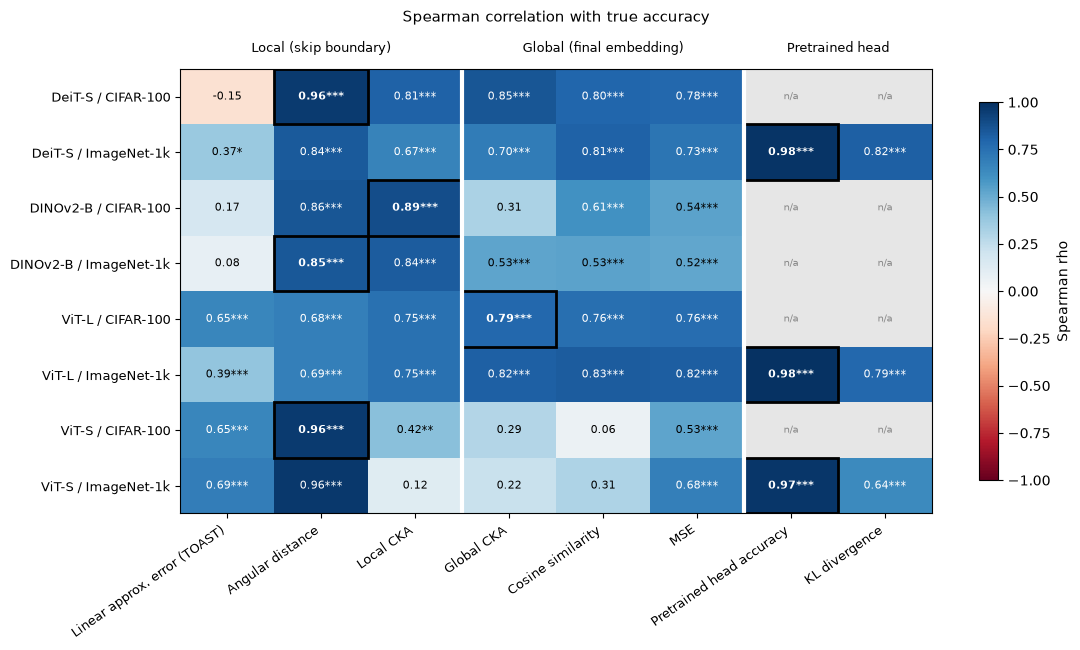

In [5]:
def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def heatmap(mat, title, cbar_label, cmap, vmin, vmax, fmt, best, names, tiers=None, out=None, pvals=None):
    mat = mat.rename(columns=names)
    values = mat.values.astype(float)
    fig, ax = plt.subplots(figsize=(1.05 * mat.shape[1] + 3, 0.55 * mat.shape[0] + 2.2))
    cmap_obj = plt.get_cmap(cmap).copy()
    cmap_obj.set_bad("#e6e6e6")
    norm = Normalize(vmin=vmin, vmax=vmax)
    im = ax.imshow(np.ma.masked_invalid(values), cmap=cmap_obj, norm=norm, aspect="auto")

    for i in range(values.shape[0]):
        row = values[i]
        best_j = None if np.isnan(row).all() else (np.nanargmax(row) if best == "max" else np.nanargmin(row))
        for j, v in enumerate(row):
            if np.isnan(v):
                ax.text(j, i, "n/a", ha="center", va="center", fontsize=7, color="#888888")
                continue
            r, g, b, _ = cmap_obj(norm(v))
            colour = "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.55 else "black"
            label = fmt.format(v) + ("" if pvals is None else stars(pvals.iat[i, j]))
            ax.text(j, i, label, ha="center", va="center", fontsize=8, color=colour,
                    fontweight="bold" if j == best_j else "normal")
        if best_j is not None:
            ax.add_patch(Rectangle((best_j - 0.5, i - 0.5), 1, 1, fill=False, lw=2, ec="black"))

    ax.set_xticks(range(mat.shape[1]))
    ax.set_xticklabels(mat.columns, rotation=35, ha="right", fontsize=9)
    ax.set_yticks(range(mat.shape[0]))
    ax.set_yticklabels(pretty_index(mat.index), fontsize=9)
    if tiers:
        start = 0
        for label, width in tiers:
            if start:
                ax.axvline(start - 0.5, color="white", lw=3)
            ax.text(start + width / 2 - 0.5, -0.75, label, ha="center", va="bottom", fontsize=9)
            start += width
    ax.set_title(title, fontsize=11, pad=34 if tiers else 8)
    fig.colorbar(im, ax=ax, shrink=0.85, label=cbar_label)
    fig.tight_layout()
    if out:
        fig.savefig(FIG_DIR / out, dpi=200, bbox_inches="tight")
    plt.show()


heatmap(rho, "Spearman correlation with true accuracy", "Spearman rho", "RdBu", -1, 1, "{:.2f}",
        "max", THESIS_METRICS, TIERS, "s2_spearman_rho.png", pvals=rho_p)

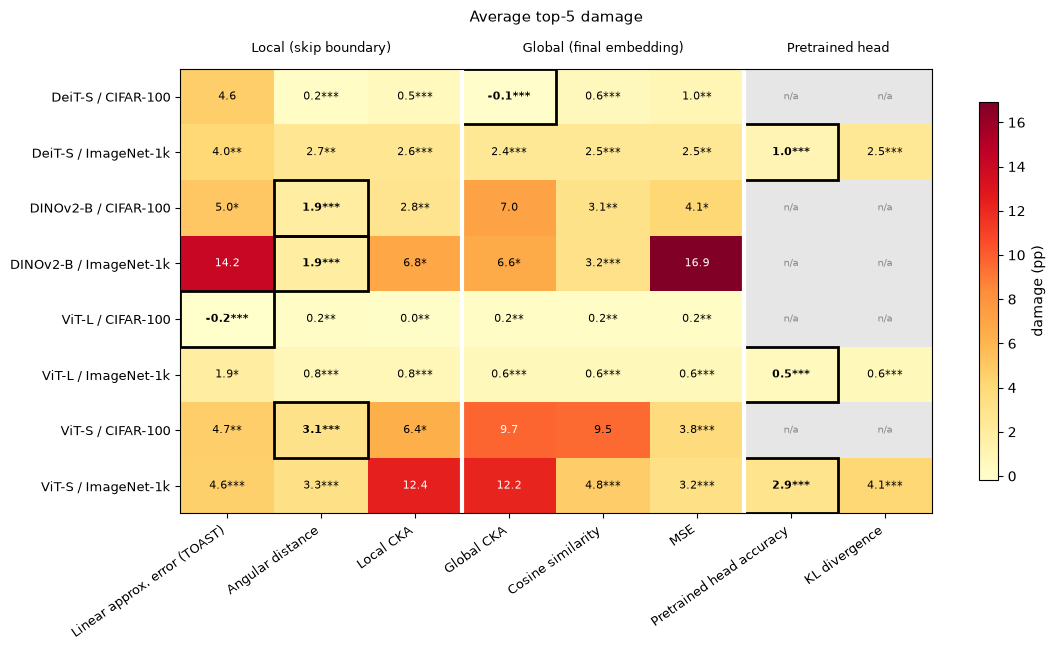

In [6]:
heatmap(damage, "Average top-5 damage", "damage (pp)", "YlOrRd", min(0, np.nanmin(damage.values)),
        np.nanmax(damage.values), "{:.1f}", "min", THESIS_METRICS, TIERS, "s2_top5_damage.png",
        pvals=damage_p)


## Summary

Mean over combos. The head metrics are averaged over their 3 ImageNet-1k combos only, so `n_combos` must be read alongside the means. `best_in` counts combos where the metric has the lowest damage among the metrics available there; ties count for each tied metric.

In [7]:
best_counts = damage.apply(lambda r: r == r.min(), axis=1).sum()
overview = pd.DataFrame({
    "metric": [THESIS_METRICS[m] for m in THESIS_METRICS],
    "n_combos": rho.notna().sum().values,
    "mean_rho": rho.mean().values,
    "min_rho": rho.min().values,
    "mean_top5_damage_pp": damage.mean().values,
    "max_top5_damage_pp": damage.max().values,
    "best_in": best_counts.values,
}).set_index("metric")
overview.to_csv(ANALYSIS / "metric_overview_s2.csv")
overview.round(2)

,n_combos,mean_rho,min_rho,mean_top5_damage_pp,max_top5_damage_pp,best_in
metric,,,,,,
Linear approx. error (TOAST),8,0.36,-0.15,4.86,14.16,1
Angular distance,8,0.85,0.68,1.75,3.26,3
Local CKA,8,0.65,0.12,4.05,12.38,0
Global CKA,8,0.57,0.22,4.84,12.18,1
Cosine similarity,8,0.59,0.06,3.06,9.54,0
MSE,8,0.67,0.52,4.05,16.91,0
Pretrained head accuracy,3,0.98,0.97,1.49,2.94,3
KL divergence,3,0.75,0.64,2.43,4.15,0


## Summary figure: angular distance vs the other metrics

One row per metric. Small grey dots are the individual (model, dataset) combos; the large dot is the mean over combos. Angular distance is highlighted. The pretrained-head metrics are only defined for 3 combos (marked), so their means are not over the same set as the others.

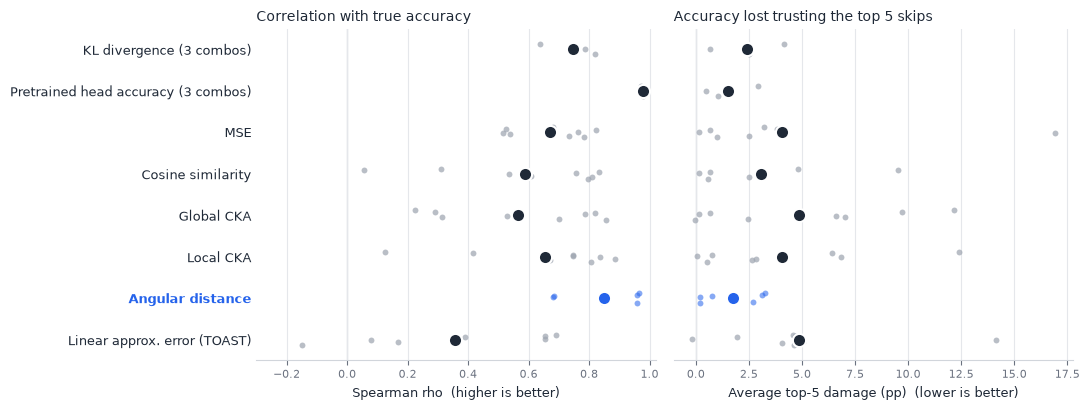

In [8]:
ACCENT, NEUTRAL, INK, MUTED = "#2563eb", "#9ca3af", "#1f2937", "#6b7280"


def dot_panel(ax, mat, xlabel, better):
    labels = []
    for y, m in enumerate(THESIS_METRICS):
        vals = mat[m].dropna().values
        hi = m == "angular_dist"
        jitter = np.linspace(-0.12, 0.12, len(vals)) if len(vals) > 1 else [0]
        ax.scatter(vals, y + np.asarray(jitter), s=18, color=ACCENT if hi else NEUTRAL,
                   alpha=0.55 if hi else 0.7, linewidths=0, zorder=2)
        ax.scatter([vals.mean()], [y], s=90, color=ACCENT if hi else INK,
                   edgecolors="white", linewidths=1.5, zorder=3)
        name = THESIS_METRICS[m] + (" (3 combos)" if len(vals) < len(combos) else "")
        labels.append(name)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=9)
    for tick, m in zip(ax.get_yticklabels(), THESIS_METRICS):
        tick.set_color(ACCENT if m == "angular_dist" else INK)
        tick.set_fontweight("bold" if m == "angular_dist" else "normal")
    ax.invert_yaxis()
    ax.set_xlabel(f"{xlabel}  ({better} is better)", fontsize=9, color=INK)
    ax.grid(axis="x", color="#e5e7eb", lw=0.8, zorder=0)
    ax.tick_params(axis="x", labelsize=8, colors=MUTED)
    ax.tick_params(axis="y", length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#d1d5db")


fig, (ax_r, ax_g) = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
dot_panel(ax_r, rho, "Spearman rho", "higher")
ax_r.axvline(0, color=MUTED, lw=0.8, zorder=1)
ax_r.set_xlim(-0.3, 1.02)
dot_panel(ax_g, damage, "Average top-5 damage (pp)", "lower")
ax_g.axvline(0, color=MUTED, lw=0.8, zorder=1)
ax_r.set_title("Correlation with true accuracy", fontsize=10, loc="left", color=INK)
ax_g.set_title("Accuracy lost trusting the top 5 skips", fontsize=10, loc="left", color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "s2_metric_summary.png", dpi=200, bbox_inches="tight")
plt.show()

### Findings (numbers computed below)

In [9]:
shared = [m for m in THESIS_METRICS if rho[m].notna().sum() == len(combos)]
head_combos = rho.index[rho["orig_head_accuracy"].notna()]
o = overview.rename(index={v: k for k, v in THESIS_METRICS.items()})
runner_mean_rho = o.loc[shared, "mean_rho"].drop("angular_dist").idxmax()
runner_min_rho = o.loc[shared, "min_rho"].drop("angular_dist").idxmax()
runner_mean_dmg = o.loc[shared, "mean_top5_damage_pp"].drop("angular_dist").idxmin()
runner_max_dmg = o.loc[shared, "max_top5_damage_pp"].drop("angular_dist").idxmin()
a = o.loc["angular_dist"]
print(f"Among the {len(shared)} metrics available on all {len(combos)} combos, angular distance has:")
print(f"  highest mean rho      {a.mean_rho:.2f}  (next: {THESIS_METRICS[runner_mean_rho]} {o.loc[runner_mean_rho, 'mean_rho']:.2f})")
print(f"  highest worst-case rho {a.min_rho:.2f}  (next: {THESIS_METRICS[runner_min_rho]} {o.loc[runner_min_rho, 'min_rho']:.2f})")
print(f"  lowest mean damage    {a.mean_top5_damage_pp:.2f} pp  (next: {THESIS_METRICS[runner_mean_dmg]} {o.loc[runner_mean_dmg, 'mean_top5_damage_pp']:.2f} pp)")
print(f"  lowest worst-case damage {a.max_top5_damage_pp:.2f} pp  (next: {THESIS_METRICS[runner_max_dmg]} {o.loc[runner_max_dmg, 'max_top5_damage_pp']:.2f} pp)")
print(f"\nOn the {len(head_combos)} combos with a pretrained head:")
print(pd.DataFrame({
    "rho": rho.loc[head_combos, ["angular_dist", "orig_head_accuracy", "kl_div"]].mean(),
    "top5_damage_pp": damage.loc[head_combos, ["angular_dist", "orig_head_accuracy", "kl_div"]].mean(),
}).rename(index=THESIS_METRICS).round(2))

Among the 6 metrics available on all 8 combos, angular distance has:
  highest mean rho      0.85  (next: MSE 0.67)
  highest worst-case rho 0.68  (next: MSE 0.52)
  lowest mean damage    1.75 pp  (next: Cosine similarity 3.06 pp)
  lowest worst-case damage 3.26 pp  (next: Cosine similarity 9.54 pp)

On the 3 combos with a pretrained head:
                           rho  top5_damage_pp
Angular distance          0.83            2.24
Pretrained head accuracy  0.98            1.49
KL divergence             0.75            2.43


## Do the best skips transfer across datasets?

For each model, Spearman rho between the true accuracy of each skip on CIFAR-100 and on ImageNet-1k (matched by span). High rho = the same skips are safe on both datasets. Below each rho: how many of the 5 best skips (by true accuracy) are the same on both datasets. Then the average top-5 damage on each dataset when picking skips with its own top 5 vs the other dataset's top 5.

In [10]:
cross_rows = []
for model in MODELS:
    cifar = raw[(raw["model"] == model) & (raw["dataset"] == "cifar100")][["span", "true_accuracy"]]
    imnet = raw[(raw["model"] == model) & (raw["dataset"] == "imagenet1k")][["span", "true_accuracy"]]
    both = cifar.merge(imnet, on="span", suffixes=("_cifar", "_imnet"))
    r, p = spearmanr(both["true_accuracy_cifar"], both["true_accuracy_imnet"])
    print(f"{MODELS[model]:10s} n={len(both):3d}  rho={r:.3f}  p={p:.2g}")

    top5_cifar = set(cifar.sort_values("true_accuracy", ascending=False)["span"].iloc[:5])
    top5_imnet = set(imnet.sort_values("true_accuracy", ascending=False)["span"].iloc[:5])
    shared = top5_cifar & top5_imnet
    print(f"           top-5 overlap = {len(shared)}/5  shared: {sorted(shared)}")
    print(f"           CIFAR-100 top 5:   {sorted(top5_cifar)}")
    print(f"           ImageNet-1k top 5: {sorted(top5_imnet)}")

    # Top-5 damage on each dataset when using the other dataset's top 5 skips instead of its own.
    acc_cifar = dict(zip(cifar["span"], cifar["true_accuracy"]))
    acc_imnet = dict(zip(imnet["span"], imnet["true_accuracy"]))
    base_cifar = baselines[(model, "cifar100")]
    base_imnet = baselines[(model, "imagenet1k")]
    own_cifar = (base_cifar - np.mean([acc_cifar[s] for s in top5_cifar])) * 100
    other_cifar = (base_cifar - np.mean([acc_cifar[s] for s in top5_imnet])) * 100
    own_imnet = (base_imnet - np.mean([acc_imnet[s] for s in top5_imnet])) * 100
    other_imnet = (base_imnet - np.mean([acc_imnet[s] for s in top5_cifar])) * 100
    print(f"           CIFAR-100 damage:   own top 5 = {own_cifar:.2f} pp, ImageNet-1k's top 5 = {other_cifar:.2f} pp")
    print(f"           ImageNet-1k damage: own top 5 = {own_imnet:.2f} pp, CIFAR-100's top 5 = {other_imnet:.2f} pp")
    cross_rows.append({
        "model": MODELS[model],
        "rho (p)": f"{r:.2f} ({p:.0e}{stars(p)})",
        "top-5 overlap": f"{len(shared)}/5",
        "CIFAR-100 damage, ImageNet-1k top 5 (pp)": round(other_cifar, 1),
        "ImageNet-1k damage, CIFAR-100 top 5 (pp)": round(other_imnet, 1),
    })

cross_table = pd.DataFrame(cross_rows).set_index("model")
cross_table


DeiT-S     n= 38  rho=0.809  p=8e-10
           top-5 overlap = 2/5  shared: ['(10,11)', '(9,10)']
           CIFAR-100 top 5:   ['(10,11)', '(7,8)', '(8,10)', '(9,10)', '(9,11)']
           ImageNet-1k top 5: ['(10,11)', '(2,3)', '(3,4)', '(4,5)', '(9,10)']
           CIFAR-100 damage:   own top 5 = -0.13 pp, ImageNet-1k's top 5 = 0.66 pp
           ImageNet-1k damage: own top 5 = 1.04 pp, CIFAR-100's top 5 = 3.53 pp
ViT-S      n= 38  rho=0.942  p=1.4e-18
           top-5 overlap = 4/5  shared: ['(2,3)', '(3,4)', '(4,5)', '(5,6)']
           CIFAR-100 top 5:   ['(2,3)', '(3,4)', '(4,5)', '(5,6)', '(6,7)']
           ImageNet-1k top 5: ['(1,2)', '(2,3)', '(3,4)', '(4,5)', '(5,6)']
           CIFAR-100 damage:   own top 5 = 2.61 pp, ImageNet-1k's top 5 = 2.78 pp
           ImageNet-1k damage: own top 5 = 2.94 pp, CIFAR-100's top 5 = 3.51 pp
DINOv2-B   n= 38  rho=0.973  p=2e-24
           top-5 overlap = 3/5  shared: ['(0,1)', '(2,3)', '(5,6)']
           CIFAR-100 top 5:   ['(0,1)', '(1

,rho (p),top-5 overlap,"CIFAR-100 damage, ImageNet-1k top 5 (pp)","ImageNet-1k damage, CIFAR-100 top 5 (pp)"
model,,,,
DeiT-S,0.81 (8e-10***),2/5,0.7,3.5
ViT-S,0.94 (1e-18***),4/5,2.8,3.5
DINOv2-B,0.97 (2e-24***),3/5,1.5,2.4
ViT-L,0.83 (3e-23***),1/5,0.1,1.7


## Appendix: every stage-1 metric

Same two measures for every metric computed, for reference only (not thesis figures).

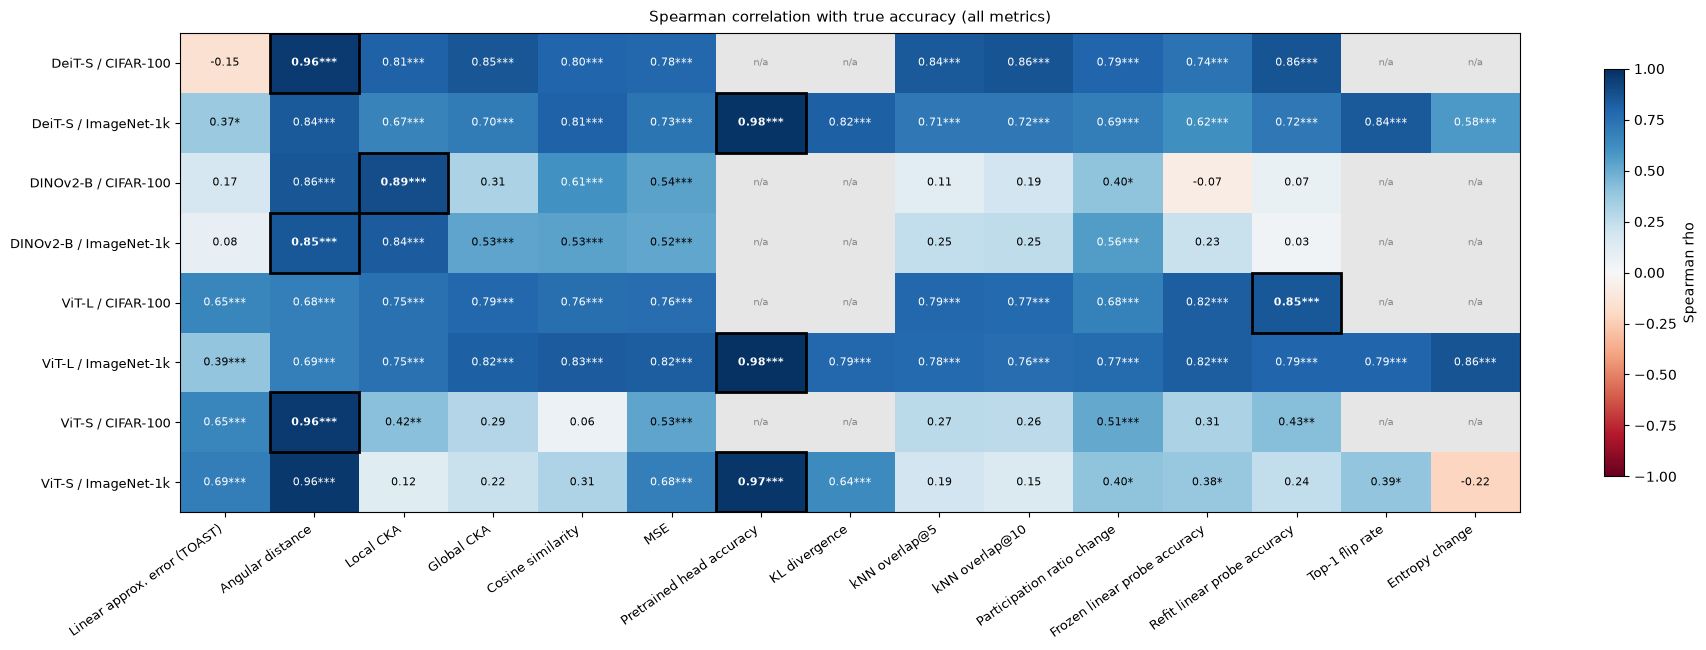

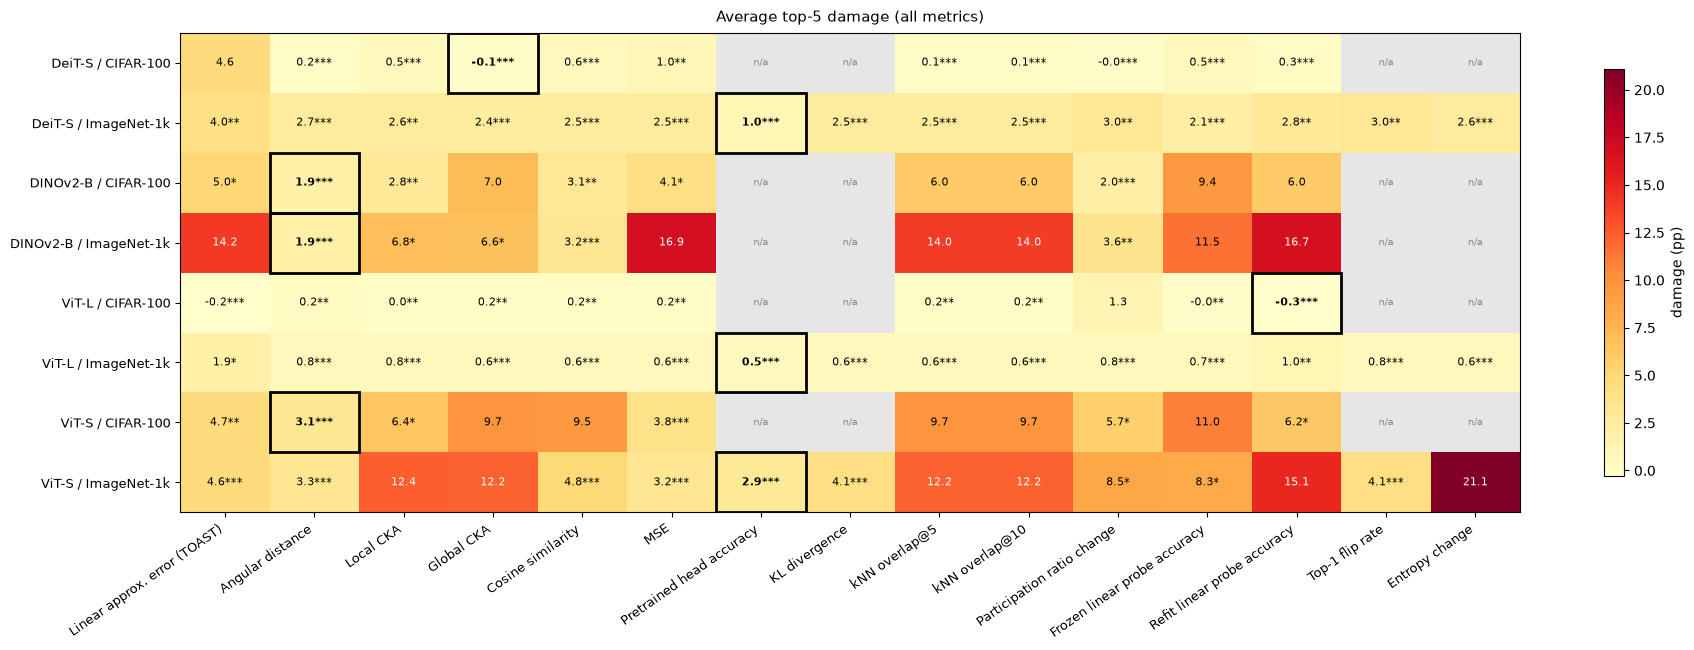

In [11]:
ALL_METRICS = {**THESIS_METRICS, **OTHER_METRICS}
rho_all, rho_p_all, damage_all, damage_p_all = evaluate(ALL_METRICS)
heatmap(rho_all, "Spearman correlation with true accuracy (all metrics)", "Spearman rho", "RdBu",
        -1, 1, "{:.2f}", "max", ALL_METRICS, out="s2_spearman_rho_all_metrics.png", pvals=rho_p_all)
heatmap(damage_all, "Average top-5 damage (all metrics)", "damage (pp)", "YlOrRd",
        min(0, np.nanmin(damage_all.values)), np.nanmax(damage_all.values), "{:.1f}", "min",
        ALL_METRICS, out="s2_top5_damage_all_metrics.png", pvals=damage_p_all)
